In [1]:
import geopandas as gpd
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from rasterio.mask import mask
from rasterio.transform import xy
from highlight_text import fig_text, ax_text

In [2]:
# Region boundary
url = (
    "https://gisco-services.ec.europa.eu/distribution/v2/"
    "nuts/geojson/NUTS_RG_01M_2024_4326_LEVL_2.geojson"
)

nuts = gpd.read_file(url).to_crs("ESRI:54009")
gdf = nuts[nuts["NUTS_NAME"] == "Grande Lisboa"]
shapes = list(gdf.geometry)

In [3]:
# Rasters
smod1975 = rasterio.open("GHS_SMOD_E1975_GLOBE_R2023A_54009_1000_V2_0_R5_C18.tif")
smod2025 = rasterio.open("GHS_SMOD_E2025_GLOBE_R2023A_54009_1000_V2_0_R5_C18.tif")

In [4]:
def clip_raster_file(raster_filename, shapes):    
    with rasterio.open(raster_filename, "r") as rasterfile:
        
        # Clip raster 
        out_image, out_transform = mask(dataset=rasterfile, shapes=shapes, crop=True)

        # Copy metadata
        out_meta = rasterfile.meta.copy()

    # Update metadata
    out_meta.update({
        "driver": "GTiff",
        "height": out_image.shape[1],
        "width": out_image.shape[2],
        "transform": out_transform
    })

    # Save clipped raster
    output_filename = raster_filename.replace(".tif", "_clipped.tif")

    with rasterio.open(output_filename, "w", **out_meta) as dest:
        dest.write(out_image)

    return output_filename

In [5]:
# Clip files
clip_raster_file("GHS_SMOD_E1975_GLOBE_R2023A_54009_1000_V2_0_R5_C18.tif", shapes)
clip_raster_file("GHS_SMOD_E2025_GLOBE_R2023A_54009_1000_V2_0_R5_C18.tif", shapes)

'GHS_SMOD_E2025_GLOBE_R2023A_54009_1000_V2_0_R5_C18_clipped.tif'

In [6]:
tifs = {
    1975: "GHS_SMOD_E1975_GLOBE_R2023A_54009_1000_V2_0_R5_C18_clipped.tif",
    2025: "GHS_SMOD_E2025_GLOBE_R2023A_54009_1000_V2_0_R5_C18_clipped.tif",
}

In [7]:
# GHS-SMOD classes
urban = [21, 22, 23, 30]
rural = [11, 12, 13]
water = [10]

# Colors
colors = {
    1: "#E8D9A8",  # rural 
    2: "#FF654F",  # urban 
    3: "#67C9E8",  # water 
}

In [8]:
# Read clipped rasters
rasters = {}
valid_masks = {}

for year, path in tifs.items():
    with rasterio.open(path) as src:
        rasters[year] = src.read(1)
        valid_masks[year] = src.read_masks(1) > 0

        if year == 1975:
            transform = src.transform
            crs = src.crs
            shape = src.shape

        else:
            # Both rasters use the same grid
            assert src.crs == crs
            assert src.shape == shape
            assert src.transform.almost_equals(transform)

In [9]:
# Classify into, rural, urban, water
classified = {}

for year, data in rasters.items():

    # Start with zeros (NoData)
    result = np.zeros(data.shape, dtype=int)

    # Assign new categories
    result[np.isin(data, rural)] = 1
    result[np.isin(data, urban)] = 2
    result[np.isin(data, water)] = 3

    # Remove NoData cells
    result[np.ma.getmaskarray(data)] = 0

    classified[year] = result

In [10]:
# Rural to urban change
old = classified[1975]
new = classified[2025]

rural_1975 = np.sum(old == 1)
rural_to_urban = np.sum((old == 1) & (new == 2))
urban_change_pct = (rural_to_urban / rural_1975 * 100 if rural_1975 > 0 else 0)

In [11]:
# Raster coords
rows, cols = np.indices(shape)
xs, ys = xy(transform, rows, cols, offset="center")
# Orig raster dims
xs = np.array(xs).reshape(shape)
ys = np.array(ys).reshape(shape)

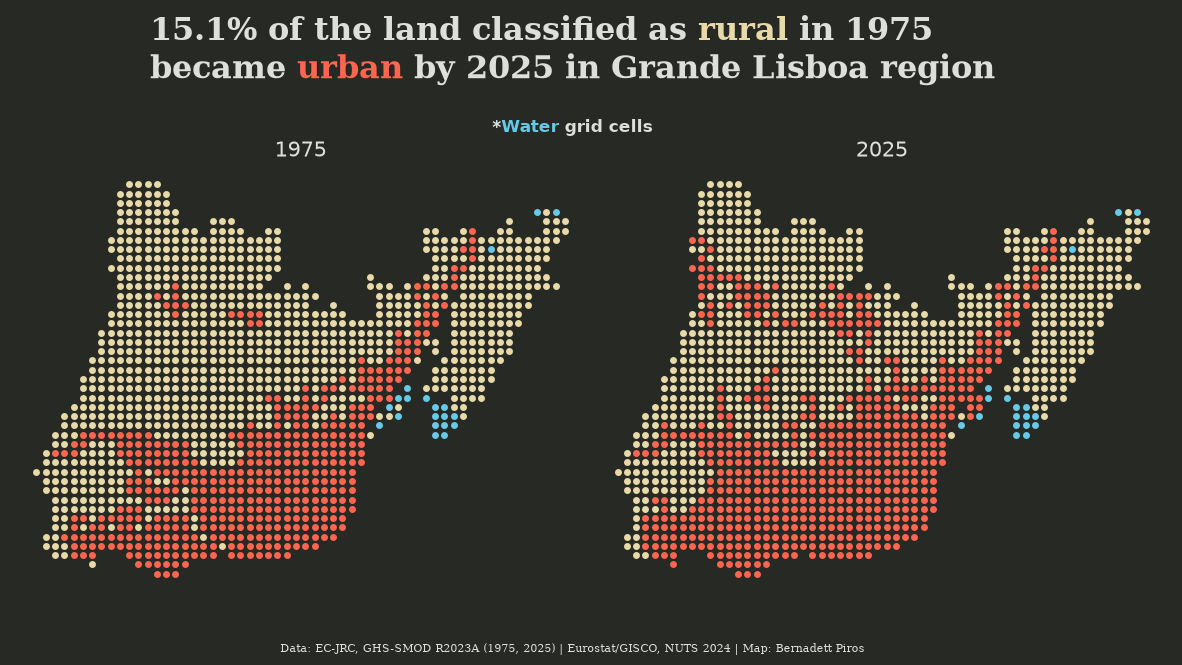

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 8), sharex=True, sharey=True, facecolor="#272924")

# Scatter
for ax, year in zip(axes, [1975, 2025]):
    data = classified[year]

    for value, label in [(1, "Rural"), (2, "Urban"), (3, "Water")]:
        selected = data == value
        ax.scatter(xs[selected], ys[selected], s=25, c=colors[value], label=label, lw=0)

    ax.set_title(str(year), size=15, color="#dddfda")
    ax.set_aspect("equal")
    ax.axis("off")

# Title
fig_text(0.5, 0.95,
         s=(
             f"{urban_change_pct:.1f}% of the land classified as "
             "<rural> in 1975\nbecame <urban> by 2025 in Grande Lisboa region"
             ),
         color="#dddfda", size=23, weight="bold", fontfamily="serif", ha="center",
         highlight_textprops=[
             {"color": colors[1]},
             {"color": colors[2]}
             ]
         )

# Subtitle
fig_text(0.5, 0.82, 
         s="*<Water> grid cells",
         color="#dddfda", size=12, weight="bold", ha="center",
         highlight_textprops=[
             {"color": colors[3]}
             ])

# Caption
fig.text(0.5, 0.15,
         "Data: EC-JRC, GHS-SMOD R2023A (1975, 2025) | "
         "Eurostat/GISCO, NUTS 2024 | "
         "Map: Bernadett Piros",
         color="#dddfda", size=8, fontfamily="serif", ha="center", va="bottom")

plt.subplots_adjust(wspace=0)
plt.show()

# Save figure
#fig.savefig("urban_rural.png", bbox_inches="tight", pad_inches=0.2) 